# Did the campaign work? Measuring incremental sales with a synthetic control

**The setup.** A six-week campaign ran in one test region. Six comparable regions didn't get it. The team wants two answers: how many sales did the campaign *add*, and did it pay for itself?

The data is synthetic with a known true effect (an 8% lift that ramps up over the first week), so the estimate can be checked against the truth.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from causal.data import make_campaign_data
from causal.impact import control_sensitivity, estimate_impact, placebo_test

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY = "#3B5BDB", "#E8590C", "#868E96"

data = make_campaign_data()
df = data.df.set_index("date")
start, end = data.campaign_start, data.campaign_end
print(f"Campaign: {start.date()} to {end.date()} ({(end - start).days + 1} days)")
df.head()

Campaign: 2025-10-08 to 2025-11-18 (42 days)


,test,control_1,control_2,control_3,control_4,control_5,control_6
date,,,,,,,
2025-01-01,9839.1,4808.4,6072.3,10274.0,6470.9,6267.6,8932.4
2025-01-02,9663.3,4915.9,6105.0,10694.2,6285.8,6402.8,8635.5
2025-01-03,10011.4,4924.6,6161.8,10624.7,6744.9,6272.9,9426.8
2025-01-04,10091.9,5415.4,6605.4,11129.4,6957.7,6973.3,9193.6
2025-01-05,10973.6,5387.8,6463.8,11286.3,7178.8,6948.7,10112.0


## 1. Look at the regions

The regions differ in size, so each is indexed to its own pre-campaign average. If the controls are useful, they should move together with the test region before the campaign.

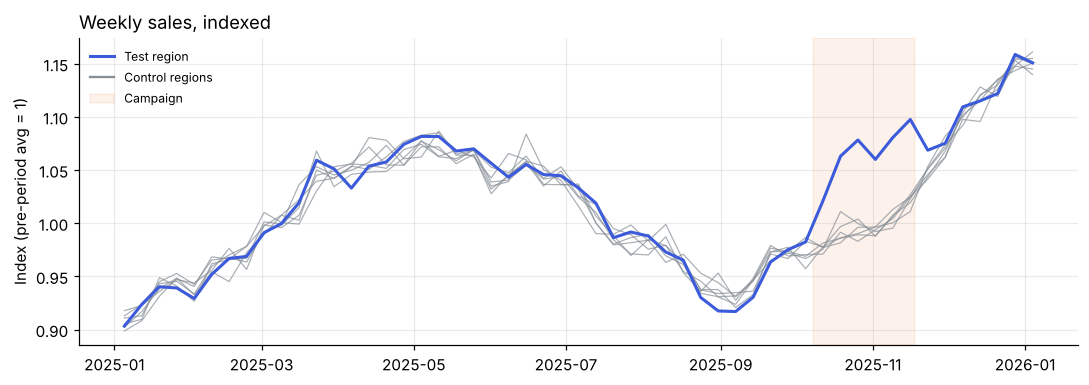

In [2]:
pre = df.loc[: start - pd.Timedelta(days=1)]
indexed = df / pre.mean()
weekly = indexed.resample("W").mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
for c in data.controls:
    ax.plot(weekly.index, weekly[c], color=GREY, lw=0.8, alpha=0.7)
ax.plot(weekly.index, weekly["test"], color=BLUE, lw=2, label="Test region")
ax.plot([], [], color=GREY, label="Control regions")
ax.axvspan(start, end, color=ORANGE, alpha=0.08, label="Campaign")
ax.set_ylabel("Index (pre-period avg = 1)")
ax.set_title("Weekly sales, indexed", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()

The regions share seasonality and shocks, and the test region pulls away during the campaign. The question is by how much.

## 2. Why "before vs. during" is the wrong comparison

The quickest answer is to compare the test region's average during the campaign with the weeks before it. But sales were also changing for reasons unrelated to the campaign (season, trend), and a simple before/after comparison credits all of it to the campaign.

In [3]:
before = df.loc[start - pd.Timedelta(days=42): start - pd.Timedelta(days=1), "test"].mean()
during = df.loc[start:end, "test"].mean()
true_cum = float(data.true_effect[start:end].sum())
true_rel = true_cum / (df.loc[start:end, "test"].sum() - true_cum)
print(f"Naive before/after lift: {during / before - 1:+.1%}")
print(f"True lift:               {true_rel:+.1%}")

Naive before/after lift: +12.8%
True lift:               +7.4%


The naive comparison almost doubles the lift: sales were rising into autumn anyway, and before/after credits all of that to the campaign. Had the season been heading down, it would have hidden a real effect instead. We need a counterfactual: what the test region would have sold *without* the campaign, over the same days.

## 3. Build the counterfactual from control regions

On the pre-campaign period, the test region is regressed on the controls: an intercept plus **non-negative** weights. The non-negativity matters: it keeps the counterfactual a blend of real regions, instead of an arbitrary linear combination that fits the past by accident.

In [4]:
result = estimate_impact(data.df, "test", data.controls, start, end)
print(f"Pre-period fit (MAPE): {result.pre_period_mape:.2%}")
result.weights.round(3).to_frame()

Pre-period fit (MAPE): 1.96%


,weight
control_1,0.313
control_2,0.272
control_3,0.160
control_4,0.449
control_5,0.156
control_6,0.158


A pre-period error of about 2% means the controls track the test region closely. If this number were large, nothing after this point should be trusted.

## 4. The effect

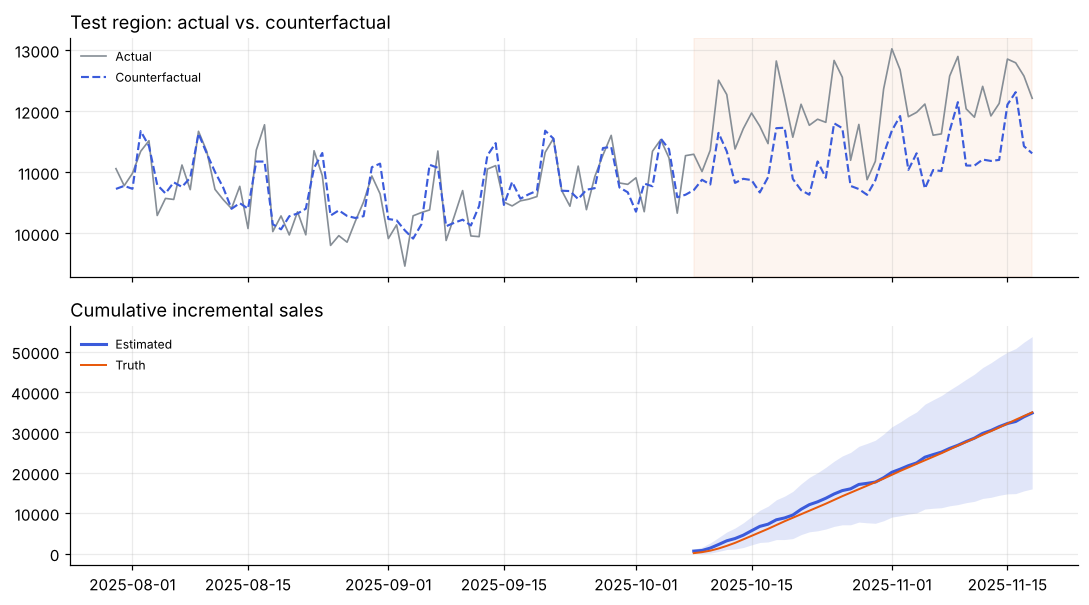

In [5]:
window = estimate_impact(data.df, "test", data.controls, start - pd.Timedelta(days=70), end, n_boot=100).daily
eff = result.daily
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
axes[0].plot(window.index, window["actual"], color=GREY, lw=1.1, label="Actual")
axes[0].plot(window.index, window["counterfactual"], color=BLUE, lw=1.4, ls="--", label="Counterfactual")
axes[0].axvspan(start, end, color=ORANGE, alpha=0.06)
axes[0].set_title("Test region: actual vs. counterfactual", loc="left")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
axes[1].fill_between(eff.index, eff["lower"].cumsum(), eff["upper"].cumsum(), color=BLUE, alpha=0.15, lw=0)
axes[1].plot(eff.index, eff["effect"].cumsum(), color=BLUE, lw=2, label="Estimated")
axes[1].plot(eff.index, data.true_effect[start:end].cumsum(), color=ORANGE, lw=1.3, label="Truth")
axes[1].set_title("Cumulative incremental sales", loc="left")
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()

In [6]:
print(result.summary())
print(f"\nTruth: {true_cum:,.0f} incremental sales, {true_rel:+.2%} lift")

Pre-period fit (MAPE): 1.96%
Cumulative incremental sales: 34,809 (90% interval 32,029 to 38,051)
Relative lift: +7.40% (90% interval +6.77% to +8.15%)

Truth: 34,969 incremental sales, +7.44% lift


The estimate lands within a fraction of a percent of the truth. (The shaded band adds up daily intervals, so it is a rough visual guide; the summary's interval for the total is the one to quote.)

## 5. Could this be noise? A placebo test

Run the exact same analysis on fake campaign dates inside the pre-period, where nothing happened. Those estimates show how big a "lift" the method produces by chance alone.

Largest placebo lift: 1.08%, placebo p-value: 0.043


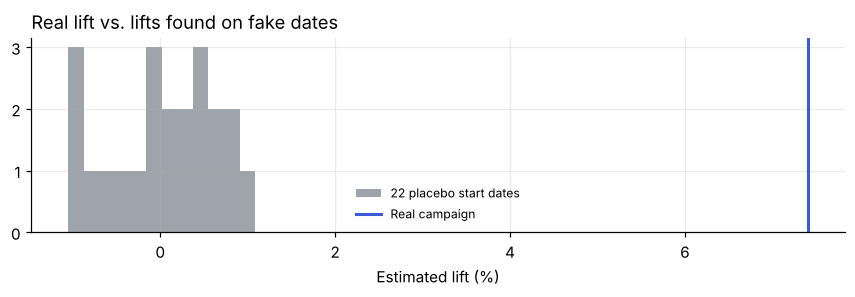

In [7]:
result.placebo_effects = placebo_test(data.df, "test", data.controls, start, 42)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(result.placebo_effects * 100, bins=12, color=GREY, alpha=0.8, label=f"{len(result.placebo_effects)} placebo start dates")
ax.axvline(result.relative_lift * 100, color=BLUE, lw=2, label="Real campaign")
ax.set_xlabel("Estimated lift (%)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Real lift vs. lifts found on fake dates", loc="left")
fig.tight_layout()
print(f"Largest placebo lift: {np.abs(result.placebo_effects).max():.2%}, placebo p-value: {result.placebo_p_value:.3f}")

Every placebo stays within about ±1%, and the real lift is around 7%. The p-value is as small as 22 placebos allow (1/23).

## 6. Does the answer depend on one region?

Drop each control in turn and re-estimate. A robust result barely moves.

In [8]:
sens = control_sensitivity(data.df, "test", data.controls, start, end)
sens.style.format("{:+.2%}", subset=["relative_lift", "lower", "upper"]).format("{:.2%}", subset=["pre_period_mape"])

,relative_lift,lower,upper,pre_period_mape
all controls,+7.40%,+6.78%,+8.16%,1.96%
without control_1,+7.42%,+6.76%,+8.17%,1.98%
without control_2,+7.44%,+6.71%,+8.22%,1.97%
without control_3,+7.35%,+6.70%,+8.12%,1.99%
without control_4,+7.31%,+6.66%,+8.07%,2.04%
without control_5,+7.44%,+6.75%,+8.18%,1.97%
without control_6,+7.42%,+6.80%,+8.17%,1.97%


Stable: every version lands between 7.3% and 7.4%.

### What contamination looks like

The most common way this method fails is **spillover**: the campaign also reaches a control region (national TV, broad online targeting), so the "untreated" baseline is partly treated. Below, control 4 receives 60% of the campaign's lift.

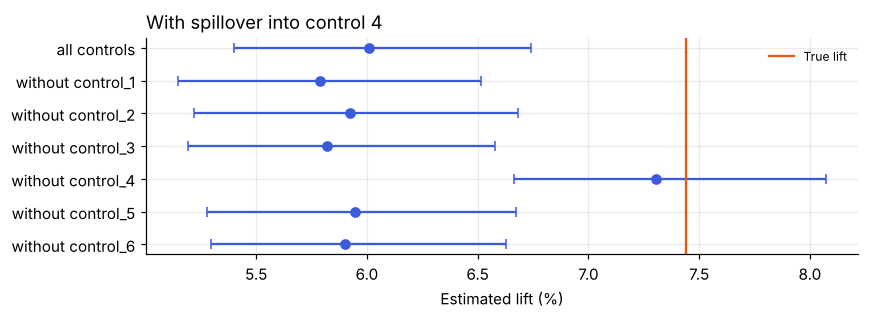

In [9]:
spill = make_campaign_data(spillover={4: 0.6})
sens_spill = control_sensitivity(spill.df, "test", spill.controls, spill.campaign_start, spill.campaign_end)
fig, ax = plt.subplots(figsize=(8, 3))
ypos = np.arange(len(sens_spill))
ax.errorbar(sens_spill["relative_lift"] * 100, ypos,
            xerr=[(sens_spill["relative_lift"] - sens_spill["lower"]) * 100, (sens_spill["upper"] - sens_spill["relative_lift"]) * 100],
            fmt="o", color=BLUE, capsize=3)
ax.axvline(true_rel * 100, color=ORANGE, lw=1.5, label="True lift")
ax.set_yticks(ypos, sens_spill.index)
ax.invert_yaxis()
ax.set_xlabel("Estimated lift (%)")
ax.set_title("With spillover into control 4", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

With all controls, the estimate drops to about 6% and its interval no longer contains the truth. Leaving out control 4 brings it straight back. This is why the sensitivity check belongs in every analysis: the contaminated region stands out immediately.

## 7. The business answer

Sales here are in euros. Assume the campaign cost €20,000 in media and the business works with a 40% contribution margin.

In [10]:
cost, margin = 20_000, 0.40
lo, hi = result.cumulative_interval
iroas = result.cumulative_effect / cost
profit = result.cumulative_effect * margin - cost
pd.DataFrame({
    "estimate": [result.cumulative_effect, iroas, profit],
    "low (90%)": [lo, lo / cost, lo * margin - cost],
    "high (90%)": [hi, hi / cost, hi * margin - cost],
}, index=["incremental revenue (€)", "incremental ROAS", "incremental profit (€)"]).round(2)

,estimate,low (90%),high (90%)
incremental revenue (€),34809.14,32029.20,38050.83
incremental ROAS,1.74,1.60,1.90
incremental profit (€),-6076.34,-7188.32,-4779.67


The campaign clearly *worked*: about €35k of incremental revenue, an incremental ROAS of roughly 1.7. But at a 40% margin it **did not pay for itself**: the margin on the extra revenue is about €14k against €20k of cost, and even the top of the interval is negative.

That distinction, "it worked" vs. "it was worth it", is the most useful thing an incrementality test gives a marketing team. Next steps would be to test a lower spend level, or to check whether the lift persists after the campaign ends, which this analysis doesn't count.